In [1]:
from pathlib import Path
import json
import numpy as np
import scipy
from scipy.integrate import solve_ivp
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
#Set up parameters, but note parts of the code below depend on alpha=beta=1.
D=12; h=1/D; alpha=beta=1.; F=2/(3*np.sqrt(3));
j=np.arange(D); a=2*np.pi*j/D
#x0 and v0 provides initial conditions
x0=.04*np.cos(a)+.015*np.sin(2*a)
v0=-np.ones(D)/np.sqrt(3)+.12*np.sin(a)
#B descripes the target flock
B=.008*np.cos(a)
styles=['-','--','-.',':']
#This function calculates the laplacian
def lap(x):return (np.roll(x,1,axis=-1)+np.roll(x,-1,axis=-1)-2*x)/h**2
def f(v):return v-v**3
def energy(x,v):
    # The difference form avoids subtracting large translation-dependent terms.
    return float(.5*np.sum(v*v)+.5/h**2*np.sum((np.roll(x,1)-x)**2))

def require(condition,message):
    """Keep numerical verification active even with Python's -O option."""
    if not condition:
        raise RuntimeError(message)

def setup(M):
    if not np.isscalar(M) or not np.isrealobj(M) or not np.isfinite(M) or M<=F:
        raise ValueError(f'M must be finite and strictly larger than F={F}')
    if (alpha,beta)!=(1.,1.):
        raise ValueError('This script implements only alpha=beta=1')
    gamma=2*max(1,1/M); a1=1/gamma; a2=gamma
    # The outer 1/2 already guarantees Eh < M/2:
    # Eh <= (M/2)*(1+8/h**2)/(13+8/h**2). No third bound is needed.
    eps=.5*min(1,M/(13+8/h**2))
    Eh=(1+8/h**2)*eps
    require(Eh<M/2,'The conservative acceleration margin is not positive')
    def u(v):
        r=np.abs(v)
        return np.where(r<a1,-M*v/a1,np.where(r<=a2,-M*np.sign(v),np.where(r<2*a2,-M*np.sign(v)*(2-r/a2),0)))
    return gamma,a1,a2,eps,Eh,u

#Used to choose T3 and T4
def duration(R,mu):
    if not np.isfinite(R) or R<0 or not np.isfinite(mu) or mu<=0:
        raise ValueError('Duration requires a finite R>=0 and control margin mu>0')
    if mu>4/(3*np.sqrt(3)):
        raise ValueError('This bound will only ensure a long enough druation if mu<=4/(3*sqrt(3))')
    return max(6*R/mu,np.sqrt(24*R/mu))
   # return max(1,12*R/mu,np.sqrt(4*(6*R+27/4*R**2)/mu),(27*R**3/(2*mu))**(1/3))

#Used to make sure T3 and T4 are sufficiently large
def qmoving(tau,R):return 3*R/tau+(6*R+27/4*R**2)/tau**2+27*R**3/(8*tau**3)

def state_array(value,default,name):
    raw=np.asarray(default if value is None else value)
    if np.iscomplexobj(raw):
        raise ValueError(f'{name} must be real-valued')
    result=np.array(raw,dtype=float,copy=True)
    if result.shape!=(D,) or not np.all(np.isfinite(result)):
        raise ValueError(f'{name} must be a finite array of length {D}')
    return result

def run(M,tol=1e-10,*,x_init=None,v_init=None,target=None,
        phase1_horizon=10000.,include_details=False):
    gamma,a1,a2,eps,Eh,feedback=setup(M)
    if not np.isfinite(tol) or tol<=0:
        raise ValueError('tol must be positive and finite')
    if not np.isfinite(phase1_horizon) or phase1_horizon<=0:
        raise ValueError('phase1_horizon must be positive and finite')
    xi=state_array(x_init,x0,'x_init'); vi=state_array(v_init,v0,'v_init')
    B=state_array(target,globals()['B'],'target')
    if np.max(np.abs(lap(B)))>=M:
        raise ValueError('Target must satisfy max(abs(lap(target))) < M')
    stopping_energy=eps**2/(8*max(1,4/h**2))
    def rhs(t,y):
        x,v=y[:D],y[D:]
        return np.r_[v,lap(x)+f(v)+feedback(v)]
    def event(t,y):
        x,v=y[:D],y[D:]
        return energy(x,v)-stopping_energy
    event.terminal=True; event.direction=-1
    if energy(xi,vi)<=stopping_energy:
        # No downward crossing is needed when the stopping condition holds now.
        sol=None; T0=0.; X0=xi.copy(); V0=vi.copy()
    else:
        sol=solve_ivp(rhs,(0,phase1_horizon),np.r_[xi,vi],method='DOP853',rtol=tol,atol=tol/100,
                      max_step=.05,dense_output=True,events=event)
        if not sol.success:
            raise RuntimeError(f'First-phase integration failed: {sol.message}')
        if len(sol.t_events[0])!=1:
            raise RuntimeError(f'First-phase stopping event was not reached by {phase1_horizon}; '
                               'this is an integration-horizon limit, not a reachability conclusion')
        T0=sol.t_events[0][0]; X0,V0=sol.y[:D,-1],sol.y[D:,-1]
    require(max(np.abs(V0))<eps and max(np.abs(lap(X0)))<eps,
            'The first-phase stopping state fails the required smallness conditions')
    braking=np.abs(V0)/eps; T1=T0+max(braking)
    X1=X0+V0*braking-.5*eps*np.sign(V0)*braking**2 #Matches with x_l(T_1)
    T2=T1+2/M; X2=X1+1/M#+T1/2
    # Work with the actual position X2 at T2, rather than conflating it
    # with the intercept X2-vb*T2 of a moving flock.
    collapse_position_at_T2=float(np.mean(X2))
    d_collapse=collapse_position_at_T2-X2
    R_collapse=max(np.abs(d_collapse)); mu_collapse=M-Eh
    tau_collapse=duration(R_collapse,mu_collapse); T3=T2+tau_collapse
    X3=np.full(D,collapse_position_at_T2+tau_collapse)
    d_target=B-X3
    R_target=max(np.abs(d_target)); mu_target=M-max(np.abs(lap(B)))
    print(R_target)
    tau_target=duration(R_target,mu_target); T4=T3+tau_target; T=T4
    #shift=collapse_position_at_T2-vb*T2-target_center
    def plan(t,phase=None):
        if phase is None:
            phase=(0 if t<T0 else 1 if t<T1 else 2 if t<T2
                   else 3 if t<T3 else 4 if t<T4 else 5)
        if phase==0:
            y=np.r_[xi,vi] if sol is None else sol.sol(t)
            x,v=y[:D],y[D:]; u=feedback(v)
        elif phase==1:
            z=t-T0; r1=np.minimum(z,braking)
            x=X0+V0*r1-.5*eps*np.sign(V0)*r1**2   #Matches eq below 2.14
            v=np.sign(V0)*np.maximum(np.abs(V0)-eps*z,0) #Matches 2.14
            dv=np.where(z<braking,-eps*np.sign(V0),0) #dot(v)
            u=dv-lap(x)-f(v) #Matches 2.13
        elif phase==2:
            # z is elapsed time, so x(T1)=X1 AND v(T1)=0.
            # X1 + M/4*(t*t-T1*T1) would have the wrong derivative.
            z=t-T1; x=X1+M/4*z*z; v=np.full(D,M/2*z)
            u=M/2-lap(X1)-f(v)
        elif phase==3:
            s=np.clip((t-T2)/tau_collapse,0,1); p=3*s*s-2*s**3
            dp=6*s*(1-s); ddp=6-12*s
            x=X2+(t-T2)+p*d_collapse
            v=1+d_collapse/tau_collapse*dp #Matches middle of pg 14
            #u=-(1+2*s**3-3s**2)*lap(X2)+12/tau_collapse*d_collapse*s(1-6)
            u=d_collapse/tau_collapse**2*ddp-lap(x)-f(v) #Good
        elif phase==4:
            s=np.clip((t-T3)/tau_target,0,1); p=3*s*s-2*s**3
            dp=6*s*(1-s); ddp=6-12*s
            x=X3+(t-T3)+p*d_target
            v=1+d_target/tau_target*dp
            u=d_target/tau_target**2*ddp-lap(x)-f(v)
        elif phase==5:
            x=X3+(t-T3)+d_target; v=np.full(D,1); u=-lap(B)
        else:
            raise ValueError('phase must be an integer from 0 through 5')
        return x,v,u
    chunks=[]
    for phase,(lo,hi,count) in enumerate([(0,T0,max(2000,int(T0/.01))),(T0,T1,600),(T1,T2,600),(T2,T3,600),(T3,T4,600),(T4,T4+2,200)]):
        tt=np.linspace(lo,hi,count if hi>lo else 1)
        dat=np.array([np.concatenate(plan(t,phase)) for t in tt])
        chunks.append((tt,dat,phase))
    maxtotal=max(np.max(np.abs(d[:,2*D:])) for t,d,p in chunks)
    maxlate=max(np.max(np.abs(d[:,2*D:])) for t,d,p in chunks if p>0)
    # Separate integration of the exact planned controls for the short later phases.
    #I believe this is used as a check to make sure everything is working correctly.
    y=np.r_[X0,V0]; errors=[]; endpoint_errors=[]
    boundaries=sorted(set([T0,*list(T0+braking),T1,T2,T3,T4]))
    for lo,hi in zip(boundaries[:-1],boundaries[1:]):
        if hi-lo<1e-13:continue
        phase=(1 if (lo+hi)/2<T1 else 2 if (lo+hi)/2<T2
               else 3 if (lo+hi)/2<T3 else 4)
        active=((lo+hi)/2-T0)<braking
        def later(t,y):
            xr,vr,u=plan(t,phase)
            if phase==1:
                # Fix the active set on this open interval: solve_ivp must
                # see its one-sided acceleration also at the interval ends.
                u=-eps*np.sign(V0)*active-lap(xr)-f(vr)
            return np.r_[y[D:],lap(y[:D])+f(y[D:])+u]
        z=solve_ivp(later,(lo,hi),y,method='DOP853',rtol=tol,atol=tol/100,
                    max_step=.01,dense_output=True)
        if not z.success:raise RuntimeError(z.message)
        y=z.y[:,-1]
        ref=np.concatenate(plan(hi,phase)[:2]); endpoint_errors.append(max(np.abs(y-ref)))
        check_times=np.unique(np.r_[z.t,(z.t[:-1]+z.t[1:])/2])
        refs=np.array([np.concatenate(plan(t,phase)[:2]) for t in check_times]).T
        errors.append(float(np.max(np.abs(z.sol(check_times)-refs))))

    # Check the requested intermediate state and all switching states,
    # independently of the separate ODE replay above. Controls may jump.
    switch_jumps=[]
    for phase,t in enumerate([T0, T1, T2, T3, T4]):
        left=np.concatenate(plan(t,phase)[:2])
        right=np.concatenate(plan(t,phase+1)[:2])
        switch_jumps.append(max(np.abs(left-right)))
    xc,vc,_=plan(T3,3)
    xt,vt,_=plan(T4,4)
    collapse_spread=float(np.ptp(xc))
    collapse_velocity_error=float(max(abs(1-vc)))
    Q_collapse=qmoving(tau_collapse,R_collapse)
    Q_target=qmoving(tau_target,R_target)
    require(max(switch_jumps)<1e-10,'Position or velocity jumps at a switch')
    require(Q_collapse<mu_collapse and Q_target<mu_target,'A final-stage control margin failed')
    require(max(errors)<1e-7,'Planned controls fail the sampled ODE replay')
    require(maxtotal<=M+1e-10,'A sampled control exceeds M')
    require(max(np.abs(lap(X1)))<Eh,'The propagated Laplacian bound failed')
    result=dict(M=M,epsilon=eps,Eh=Eh,T0=T0,T1=T1,T2=T2,T3=T3,T4=T4,T=T,
                tau_collapse=tau_collapse,tau_target=tau_target,
                R_collapse=R_collapse,R_target=R_target,
                mu_collapse=mu_collapse,mu_target=mu_target,
                Q_collapse=Q_collapse,Q_target=Q_target,#target_shift=shift,
                collapse_spread=collapse_spread, #This ensures that everything collapses to the same point
                collapse_velocity_error=collapse_velocity_error,
                #target_translation_error=target_translation_error,target_velocity_error=target_velocity_error,
                max_switch_state_jump=max(switch_jumps),
                max_control=maxtotal,max_later_control=maxlate,
                lap_after_braking=max(np.abs(lap(X1))),ode_check=max(errors),
                ode_endpoint_check=max(endpoint_errors),
                stopping_energy=stopping_energy,first_phase_final_energy=energy(X0,V0),
                chunks=chunks,final_state=y)
    result['details']=dict(plan=plan,first_phase_solution=sol,X0=X0,V0=V0,
                               X1=X1,X2=X2,X3=X3,braking=braking,target=B,
                               initial_x=xi,initial_v=vi,boundaries=boundaries)
    return result

In [3]:
def reproduce():
    main=run(1.)
    fig,axs=plt.subplots(4,2,figsize=(10.4,9.1),sharex='col',layout='constrained')
    for col in range(2):
        for tt,dat,phase in main['chunks']:
            xx,vv,uu=dat[:,:D],dat[:,D:2*D],dat[:,2*D:]
            for k in range(D):
                axs[0,col].plot(tt,xx[:,k]-np.mean(xx,axis=1),lw=.8,ls=styles[k%4],alpha=.8)
                axs[1,col].plot(tt,vv[:,k],lw=.8,ls=styles[k%4],alpha=.8)
                axs[2,col].plot(tt,lap(xx)[:,k],lw=.8,ls=styles[k%4],alpha=.8)
            axs[3,col].plot(tt,np.max(np.abs(uu),axis=1),'k',lw=1.2)
        axs[3,col].axhline(1,color='black',ls='--',lw=1,label='bound M')
        for ax in axs[:,col]:
            for key in ['T0','T1','T2','T3','T4']:ax.axvline(main[key],color='.55',ls=':',lw=.8)
            ax.grid(alpha=.18)
        axs[3,col].set_xlabel('Time')
    axs[0,0].set_title('Full trajectory');axs[0,1].set_title('Final phases (expanded)')
    axs[0,0].set_ylabel('Position minus mean position')
    axs[1,0].set_ylabel('Site velocities');axs[2,0].set_ylabel('Discrete Laplacian');axs[3,0].set_ylabel('Maximum control magnitude')
    axs[3,0].legend(loc='best',fontsize=9)
    axs[3,1].set_xlim(main['T0']-.15,main['T4']+.2)
    axs[2,1].set_ylim(-.43,.43)
    rows=[]
    timestable=[]
    for ratio in [.002,.005,.01,.02,.05,.1,.2,.5,1.]:
        m=F*(1+ratio); result=run(m)
        row={k:float(v) for k,v in result.items() if np.isscalar(v)};row['relative_gap']=ratio
        rows.append(row)
        print('threshold',ratio,'T',result['T'],'bound',flush=True)
        times={'relative_gap': ratio,
        'M': m,
        'T0': result['T0'],
        'T1': result['T1'],
        'T2': result['T2'],
        'T3': result['T3'],
        'T4': result['T4']}
        timestable.append(times)

    df=pd.DataFrame(timestable)
    display(timestable)
    fig,ax=plt.subplots(figsize=(7.5,4.2),layout='constrained')
    ax.semilogx([r['relative_gap'] for r in rows],[r['T'] for r in rows],'o-',color='#163d73',label='Observed construction time')
    ax.set_xlabel(r'Relative threshold gap $(M-F_*)/F_*$');ax.set_ylabel('Steering time');ax.grid(which='both',alpha=.2);ax.legend()

    tight=run(1.,tol=2e-12)
    verification={
     'python_dependencies':{'numpy':np.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__},
     'main':{k:float(v) for k,v in main.items() if np.isscalar(v)},
     'tight_tolerance_T_difference':float(abs(main['T']-tight['T'])),
     'tight_tolerance_ode_check':float(tight['ode_check']),
     'maximum_threshold_control_excess':float(max(r['max_control']-r['M'] for r in rows)),
     'minimum_threshold_margin_after_braking':float(min(r['Eh']-r['lap_after_braking'] for r in rows)),
     'maximum_threshold_ode_check':float(max(r['ode_check'] for r in rows)),
     'maximum_threshold_collapse_spread':float(max(r['collapse_spread'] for r in rows)),
     'maximum_threshold_switch_state_jump':float(max(r['max_switch_state_jump'] for r in rows)),
     #'maximum_threshold_target_translation_error':float(max(r['target_translation_error'] for r in rows)),
     'threshold_study':rows,
    }
    require(main['max_control']<=1+1e-10,'The main example exceeds M=1')
    require(all(r['max_control']<=r['M']+1e-10 and r['Q_collapse']<r['mu_collapse']
                and r['Q_target']<r['mu_target'] and r['lap_after_braking']<r['Eh'] for r in rows),
                    'A threshold-study control check failed')
    tex=r'''For $M=1$, the switching times are $T_0=%.6f$, $T_1=%.6f$, $T_2=%.6f$, $T_3=%.6f$, and $T_4=%.6f$. The last two stages have separate durations $T_3-T_2=%.6f$ and $T_4-T_3=%.6f$. At $T_3$ all positions coincide: the computed spread is $%.2e$, and the common-velocity error is $%.2e$. The sampled maximum control magnitude is $%.6f$; after the first phase it is $%.6f$. The post-braking Laplacian norm is $%.3e$, below the conservative bound $E_h=%.6f$. A separate integration of the planned controls after $T_0$, split at every switching time, has a maximum sampled state error of $%.2e$, evaluated at accepted solver steps and their midpoints. Tightening the relative tolerance to $2\times10^{-12}$ changes the reported arrival time by $%.2e$. These numerical checks are floating-point diagnostics; the script checks the sufficient inequality for each of the two final stages separately.
    '''%(main['T0'],main['T1'],main['T2'],main['T3'],main['T4'],main['tau_collapse'],main['tau_target'],main['collapse_spread'],main['collapse_velocity_error'],#main['target_translation_error'],
         main['max_control'],main['max_later_control'],main['lap_after_braking'],main['Eh'],main['ode_check'],verification['tight_tolerance_T_difference'])
    print(tex)
    import re
    print(json.dumps({k:v for k,v in verification.items() if k!='threshold_study'},indent=2))

0.47100891275506024
0.8329601497619558
threshold 0.002 T 106.30306618801552 bound
0.7785387964593251
threshold 0.005 T 100.90995956157899 bound
0.6923392648998625
threshold 0.01 T 92.62464254470879 bound
0.5326460607920038
threshold 0.02 T 78.07090622009167 bound
0.1426842281228929
threshold 0.05 T 46.987724684941455 bound
0.2865076807027242
threshold 0.1 T 50.53298582044191 bound
0.6656668491576085
threshold 0.2 T 58.78383913515649 bound
0.8490526429659272
threshold 0.5 T 47.89293802223875 bound
0.6818409562469774
threshold 1.0 T 35.13795180448789 bound


[{'relative_gap': 0.002,
  'M': np.float64(0.38566997981867),
  'T0': np.float64(36.193195586867944),
  'T1': np.float64(36.200463929588594),
  'T2': np.float64(41.38624479057326),
  'T3': np.float64(41.39076641219598),
  'T4': np.float64(106.30306618801552)},
 {'relative_gap': 0.005,
  'M': np.float64(0.38682468035704926),
  'T0': np.float64(35.95320111206476),
  'T1': np.float64(35.96016235181929),
  'T2': np.float64(41.13046326993535),
  'T3': np.float64(41.13517376532911),
  'T4': np.float64(100.90995956157899)},
 {'relative_gap': 0.01,
  'M': np.float64(0.38874918125434804),
  'T0': np.float64(35.58881793190329),
  'T1': np.float64(35.59636195432023),
  'T2': np.float64(40.741067323336694),
  'T3': np.float64(40.74570168335359),
  'T4': np.float64(92.62464254470879)},
 {'relative_gap': 0.02,
  'M': np.float64(0.39259818304894556),
  'T0': np.float64(34.88344844372065),
  'T1': np.float64(34.889906771135074),
  'T2': np.float64(39.98417385222001),
  'T3': np.float64(39.988813772584

0.47100891242904797
For $M=1$, the switching times are $T_0=22.649432$, $T_1=22.659214$, $T_2=24.659214$, $T_3=24.662854$, and $T_4=28.750748$. The last two stages have separate durations $T_3-T_2=0.003640$ and $T_4-T_3=4.087894$. At $T_3$ all positions coincide: the computed spread is $0.00e+00$, and the common-velocity error is $0.00e+00$. The sampled maximum control magnitude is $1.000000$; after the first phase it is $0.500008$. The post-braking Laplacian norm is $1.435e-05$, below the conservative bound $E_h=0.494850$. A separate integration of the planned controls after $T_0$, split at every switching time, has a maximum sampled state error of $1.03e-13$, evaluated at accepted solver steps and their midpoints. Tightening the relative tolerance to $2\times10^{-12}$ changes the reported arrival time by $1.10e-08$. These numerical checks are floating-point diagnostics; the script checks the sufficient inequality for each of the two final stages separately.
    
{
  "python_dependenc

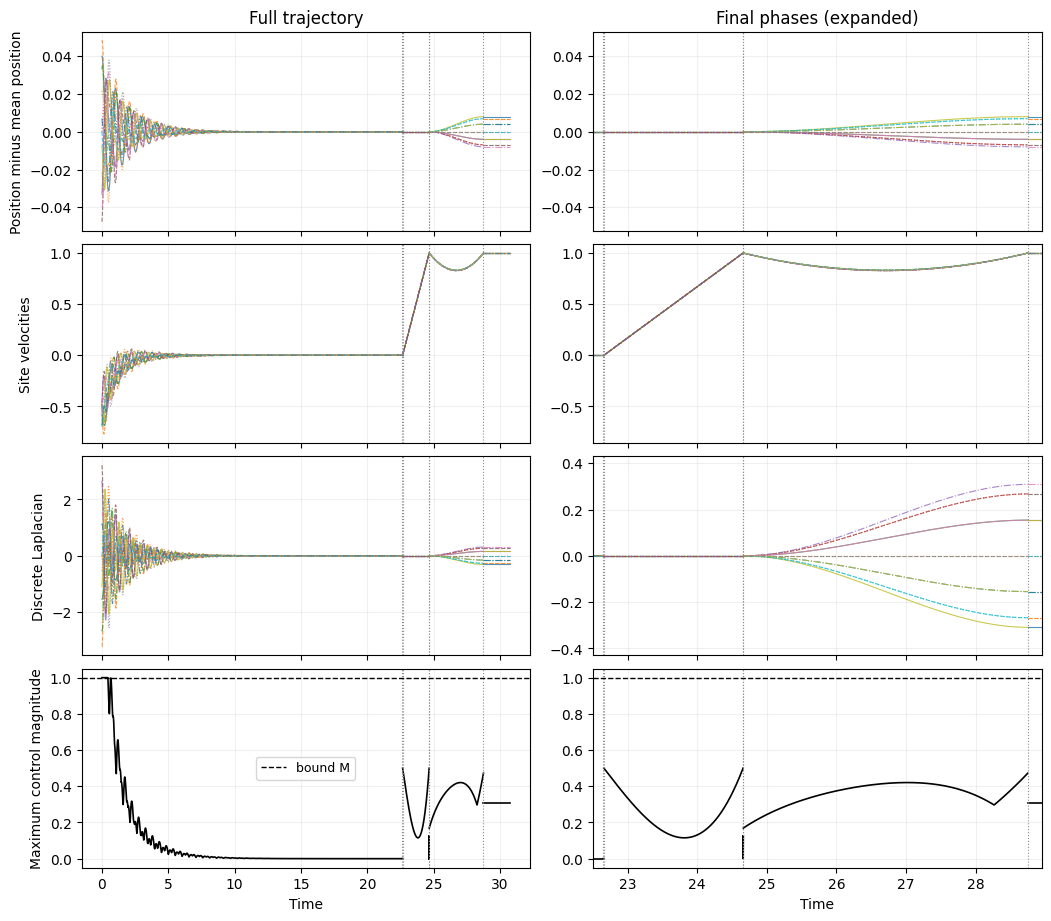

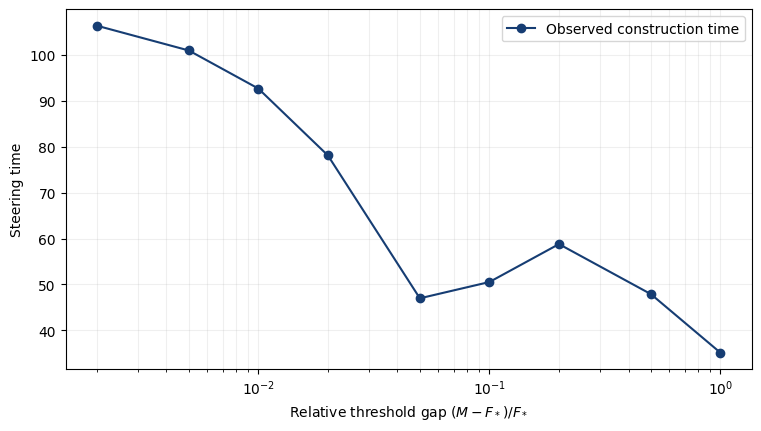

In [4]:
reproduce()